# B4 - Object Detection with a pretrained YOLOv8

Uses `yolov8n.pt` (nano, COCO-pretrained, 80 classes) via Ultralytics. No training - this is inference + interpretation of bounding boxes, class labels and confidence scores. Reports per-image detections and inference time on 5-10 images, plus a short video.

In [1]:
import time, json, urllib.request
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, cv2
from ultralytics import YOLO

OUT = Path("outputs/yolo"); OUT.mkdir(parents=True, exist_ok=True)
IMG = Path("yolo_inputs"); IMG.mkdir(exist_ok=True)
model = YOLO("yolov8n.pt")
print("classes:", len(model.names), "| device:", model.device if hasattr(model, "device") else "n/a")

classes: 80 | device: cpu


## 1. Sample inputs
Ultralytics ships two demo images (`bus.jpg`, `zidane.jpg`); we add public-domain/CC images from the Ultralytics assets and Wikimedia, so the set has people, vehicles, animals and everyday objects. Any image you drop into `yolo_inputs/` is also picked up.

In [2]:
URLS = {
    "bus.jpg":      "https://ultralytics.com/images/bus.jpg",
    "zidane.jpg":   "https://ultralytics.com/images/zidane.jpg",
    "cats.jpg":     "http://images.cocodataset.org/val2017/000000039769.jpg",
    "living_room.jpg": "http://images.cocodataset.org/val2017/000000000139.jpg",
    "bedroom.jpg":     "http://images.cocodataset.org/val2017/000000000632.jpg",
    "stop_sign.jpg":   "http://images.cocodataset.org/val2017/000000000724.jpg",
    "skier.jpg":       "http://images.cocodataset.org/val2017/000000000785.jpg",
    "baseball.jpg":    "http://images.cocodataset.org/val2017/000000000872.jpg",
}
for name, u in URLS.items():
    f = IMG / name
    if not f.exists():
        try:
            req = urllib.request.Request(u, headers={"User-Agent": "Mozilla/5.0"})
            f.write_bytes(urllib.request.urlopen(req, timeout=30).read())
        except Exception as e:
            print("skip", name, e)
images = sorted(p for p in IMG.glob("*") if p.suffix.lower() in {".jpg", ".jpeg", ".png"})
print(len(images), "images:", [p.name for p in images])

8 images: ['baseball.jpg', 'bedroom.jpg', 'bus.jpg', 'cats.jpg', 'living_room.jpg', 'skier.jpg', 'stop_sign.jpg', 'zidane.jpg']


## 2. Run inference
`conf=0.25` (default) keeps detections with confidence >= 25 %; NMS IoU 0.7. The first call includes CUDA/model warm-up, so we do one throw-away run and then time each image. `result.speed` gives preprocess / inference / postprocess in ms.

In [3]:
model.predict(str(images[0]), verbose=False)          # warm-up (not timed)
rows, annotated = [], {}
for p in images:
    t0 = time.perf_counter()
    r = model.predict(str(p), conf=0.25, verbose=False)[0]
    wall = (time.perf_counter() - t0) * 1000
    annotated[p.name] = r.plot()[:, :, ::-1]           # BGR -> RGB with boxes drawn
    cv2.imwrite(str(OUT / f"annotated_{p.name}"), r.plot())
    cls = [model.names[int(c)] for c in r.boxes.cls]
    conf = r.boxes.conf.cpu().numpy()
    rows.append(dict(image=p.name, n_detections=len(cls), classes=", ".join(f"{k}x{cls.count(k)}" for k in sorted(set(cls))),
                     mean_conf=round(float(conf.mean()), 3) if len(conf) else None,
                     min_conf=round(float(conf.min()), 3) if len(conf) else None,
                     max_conf=round(float(conf.max()), 3) if len(conf) else None,
                     inference_ms=round(r.speed["inference"], 1), total_ms=round(wall, 1)))
summary = pd.DataFrame(rows); summary.to_csv(OUT / "yolo_image_summary.csv", index=False)
summary

,image,n_detections,classes,mean_conf,min_conf,max_conf,inference_ms,total_ms
0,baseball.jpg,3,"personx2, sports ballx1",0.513,0.250,0.727,4.3,10.2
1,bedroom.jpg,7,"bedx1, bookx2, bottlex1, chairx1, potted plantx2",0.606,0.255,0.909,14.0,22.6
2,bus.jpg,6,"busx1, personx4, stop signx1",0.656,0.256,0.873,8.8,18.3
3,cats.jpg,5,"catx2, couchx1, remotex2",0.635,0.324,0.888,11.0,15.0
4,living_room.jpg,13,"chairx5, clockx1, dining tablex2, personx1, po...",0.484,0.266,0.927,8.2,19.0
5,skier.jpg,2,"personx1, skisx1",0.723,0.544,0.902,6.7,16.7
6,stop_sign.jpg,3,"stop signx2, truckx1",0.537,0.298,0.966,7.4,17.0
7,zidane.jpg,3,"personx2, tiex1",0.649,0.292,0.836,10.6,15.6


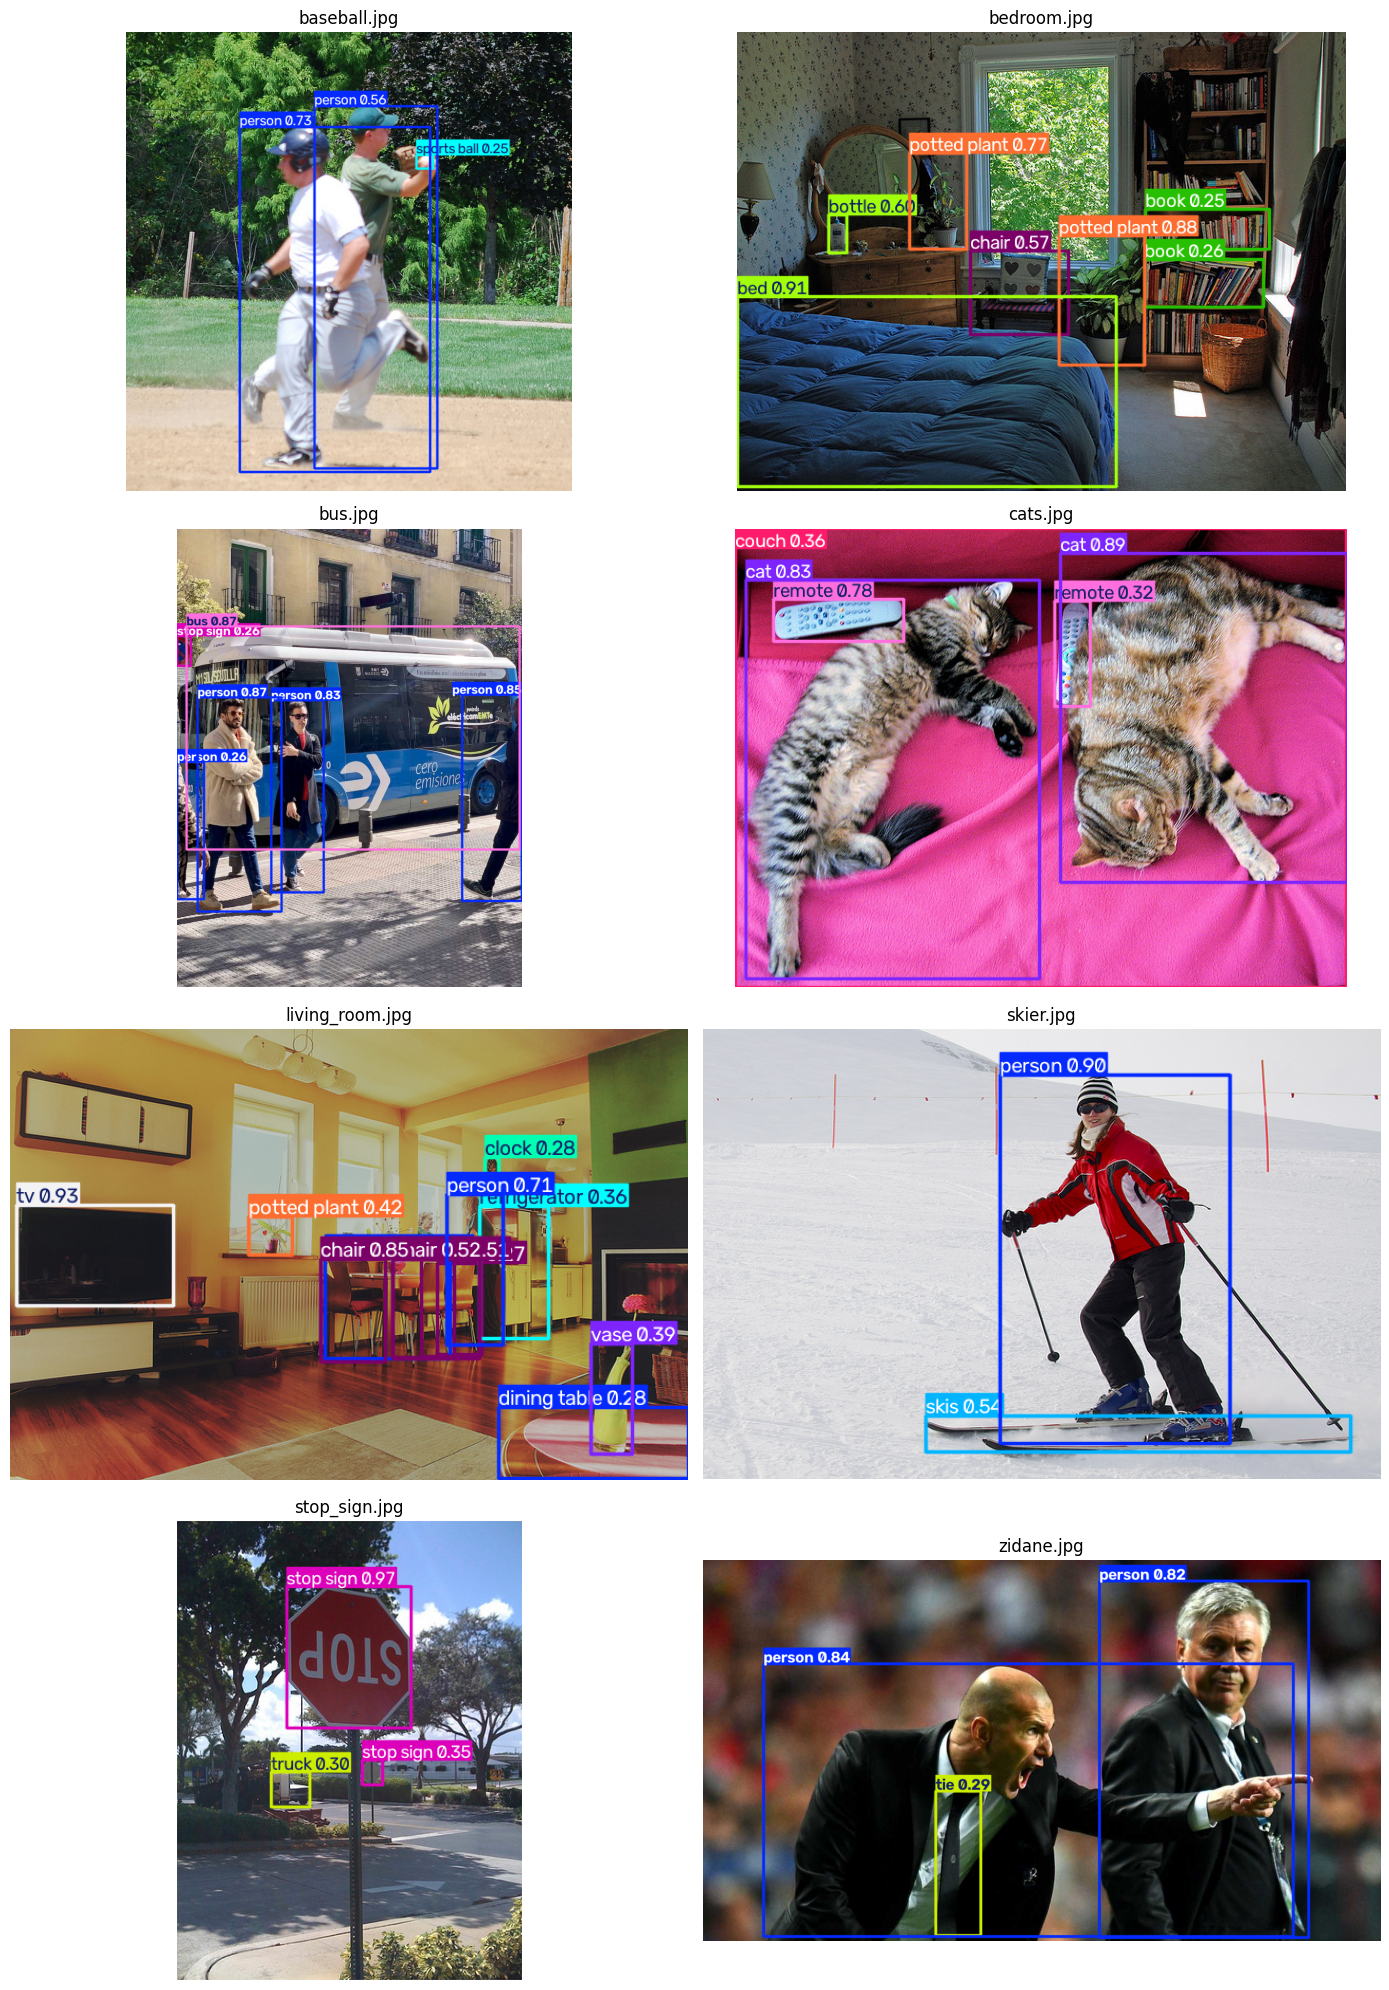

In [4]:
n = len(annotated); cols = 2; rws = (n + 1) // 2
fig, ax = plt.subplots(rws, cols, figsize=(14, 5 * rws))
for a, (name, img) in zip(ax.ravel(), annotated.items()):
    a.imshow(img); a.set_title(name); a.axis("off")
for a in ax.ravel()[n:]: a.axis("off")
plt.tight_layout(); plt.savefig(OUT / "yolo_grid.png", dpi=110); plt.show()

## 3. Interpreting one detection
Each box has: `xyxy` pixel corners, `cls` COCO class id -> name, `conf` = objectness x class probability.

In [5]:
r = model.predict(str(images[0]), verbose=False)[0]
det = pd.DataFrame([dict(label=model.names[int(c)], confidence=round(float(s), 3),
                         x1=int(b[0]), y1=int(b[1]), x2=int(b[2]), y2=int(b[3]),
                         w=int(b[2]-b[0]), h=int(b[3]-b[1])) for b, c, s in zip(r.boxes.xyxy.cpu().numpy(), r.boxes.cls, r.boxes.conf)])
print(images[0].name, "| image size (h,w):", r.orig_shape); det

baseball.jpg | image size (h,w): (640, 621)


,label,confidence,x1,y1,x2,y2,w,h
0,person,0.727,158,132,423,613,265,480
1,person,0.562,262,103,433,608,170,504
2,sports ball,0.250,404,171,427,190,23,18


In [6]:
# effect of the confidence threshold
rows = []
for th in [0.1, 0.25, 0.5, 0.75]:
    cnts = [len(model.predict(str(p), conf=th, verbose=False)[0].boxes) for p in images]
    rows.append(dict(conf_threshold=th, total_detections=sum(cnts)))
thr = pd.DataFrame(rows); thr.to_csv(OUT / "yolo_threshold.csv", index=False); thr

,conf_threshold,total_detections
0,0.10,91
1,0.25,42
2,0.50,25
3,0.75,16


## 4. Video inference
No webcam is assumed. We build a ~5 s clip by panning/zooming over the living-room image (so it works offline and reproducibly), run `model.predict` frame-by-frame and write an annotated mp4. To use your own clip set `VIDEO = 'path.mp4'`; for a webcam use `source=0`.

{'frames': 75, 'avg_inference_ms': 4.4, 'est_fps': 227.3, 'avg_dets_per_frame': 13.89, 'classes_seen': {'chair': 231, 'vase': 188, 'person': 154, 'potted plant': 120, 'tv': 116, 'dining table': 90, 'clock': 62, 'refrigerator': 59, 'cup': 13, 'bottle': 9}}


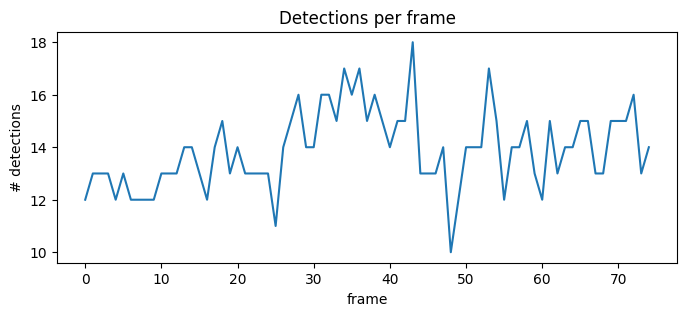

In [7]:
VIDEO = None          # e.g. "my_clip.mp4"
if VIDEO is None:
    VIDEO = str(IMG / "synthetic_clip.mp4")
    base = cv2.imread(str(IMG / "living_room.jpg") if (IMG / "living_room.jpg").exists() else str(images[0]))
    H, W = base.shape[:2]; fps, n_frames = 15, 75
    vw = cv2.VideoWriter(VIDEO, cv2.VideoWriter_fourcc(*"mp4v"), fps, (640, 480))
    for i in range(n_frames):                           # slow pan + zoom-in
        z = 1.0 + 0.3 * i / n_frames
        cw, ch = int(W / z), int(H / z)
        x0 = int((W - cw) * i / n_frames); y0 = (H - ch) // 2
        vw.write(cv2.resize(base[y0:y0 + ch, x0:x0 + cw], (640, 480)))
    vw.release()

cap = cv2.VideoCapture(VIDEO); fps = cap.get(cv2.CAP_PROP_FPS) or 15
w, h = int(cap.get(3)), int(cap.get(4))
out_path = OUT / "annotated_video.mp4"
vw = cv2.VideoWriter(str(out_path), cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h))
ms, dets, per_frame = [], [], []
while True:
    ok, frame = cap.read()
    if not ok: break
    r = model.predict(frame, conf=0.25, verbose=False)[0]
    ms.append(r.speed["inference"]); per_frame.append(len(r.boxes))
    dets += [model.names[int(c)] for c in r.boxes.cls]
    vw.write(r.plot())
cap.release(); vw.release()
vid = dict(frames=len(ms), avg_inference_ms=round(float(np.mean(ms)), 1), est_fps=round(1000 / float(np.mean(ms)), 1),
           avg_dets_per_frame=round(float(np.mean(per_frame)), 2), classes_seen=pd.Series(dets).value_counts().to_dict())
print(vid)
plt.figure(figsize=(8, 3)); plt.plot(per_frame); plt.xlabel("frame"); plt.ylabel("# detections"); plt.title("Detections per frame")
plt.savefig(OUT / "yolo_video_detections.png", dpi=120); plt.show()

In [8]:
import json
res = dict(images=len(images), avg_inference_ms=float(summary["inference_ms"].mean()),
           total_detections=int(summary["n_detections"].sum()), mean_confidence=float(summary["mean_conf"].mean()),
           video=vid, model="yolov8n (COCO, 80 classes)")
p = Path("outputs/results.json"); r = json.loads(p.read_text()) if p.exists() else {}
r["YOLO"] = res; p.write_text(json.dumps(r, indent=2)); res

{'images': 8,
 'avg_inference_ms': 8.875,
 'total_detections': 42,
 'mean_confidence': 0.600375,
 'video': {'frames': 75,
  'avg_inference_ms': 4.4,
  'est_fps': 227.3,
  'avg_dets_per_frame': 13.89,
  'classes_seen': {'chair': 231,
   'vase': 188,
   'person': 154,
   'potted plant': 120,
   'tv': 116,
   'dining table': 90,
   'clock': 62,
   'refrigerator': 59,
   'cup': 13,
   'bottle': 9}},
 'model': 'yolov8n (COCO, 80 classes)'}

## 5. Observations
- YOLO is a *single-stage* detector: one forward pass predicts boxes, classes and confidences, which is why the nano model runs in a few ms/image on a GPU.
- Confidence is a calibration-imperfect score: raising the threshold removes false positives but also true small/occluded objects (see threshold table).
- Typical failure modes visible in the outputs: small or heavily occluded objects are missed, and crowded scenes can produce overlapping/duplicate-class boxes.